### Build A Basic Chatbot with Langgraph(GRAPH API)

In [9]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages # its a reducer, it just append messages to the stategraph instead of replacing them

In [10]:
class State(TypedDict):
    # Messages have the type "list" . The 'add_messages' function
    #in the annotation defines how this state key should ne updated
    # (in this case, it appends messages to the list, rather that overwriting them)
    messages:Annotated[list,add_messages]



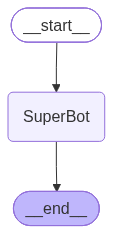

In [55]:
graph_builder

In [12]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [13]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model = "qwen/qwen3.8-27b")

In [14]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x000001F313150CE0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F3146A5730>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [15]:
llm = init_chat_model("groq:qwen/qwen3.8-27b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x000001F3146A6090>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F3146A65D0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [16]:
def chatbot(state:State):
    return{"messages":[llm.invoke(state["messages"])]}

In [17]:
graph_builder = StateGraph(State)
## adding node
graph_builder.add_node("llmchatbot",chatbot)
## addindg edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

#compile the graph
graph = graph_builder.compile()


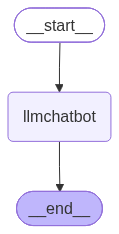

In [18]:
#visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [19]:
response = graph.invoke({"messages":"hi"})

In [20]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [21]:
for event in graph.stream({"messages":"Hi How are You?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hi! I'm doing well, thank you for asking. How are you doing today?

Is there anything specific I can help you with, or would you just like to chat?


## Chatbot with tool

In [22]:
from langchain_tavily import TavilySearch
tool = TavilySearch(max_results = 2)
tool.invoke ("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

### Custom Function

In [23]:
def multiply(a:int, b:int)->int:
    """"Multiply a and b
    Args:
        a (int): first int
        b (int): second int
    
    Returns:
        int: output int
    
    
    """
    return a*b

In [24]:
tools = [tool,multiply]
llm_with_tool = llm.bind_tools(tools)

In [25]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, client=<groq.resources.chat.completions.Completions object at 0x000001F3146A6090>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001F3146A65D0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'stri

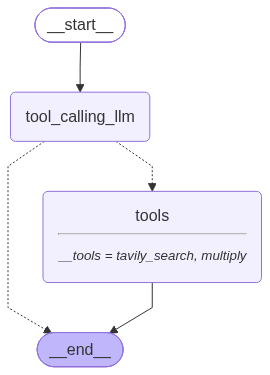

In [26]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node defination
def tool_calling_llm(state:State):
    return  {"messages":[llm_with_tool.invoke(state["messages"])]}






##graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))




## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message(result) from assistant is a tool call->tools_condition routes to tools
    #if the latest message(result) is not a tool call ->tools_condition routes to END
    tools_condition
)

builder.add_edge("tools",END)

##compile the graph
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [27]:
response =graph.invoke({"messages":"What is the recent ai news  "})

In [28]:
response['messages'][-1].content

'{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "For a tech expert, these October 2026 updates represent significant advancements in model capabilities, development tools, and hardware infrastructure. Key takeaways include the release of Gemini 4 Argon for complex coding and financial workflows, and the announcement of Gemini 4 Carbon, a model specialized in long-horizon engineering and cybersecurity defense. Developers can now build personal AI apps via Google AI Studio for direct installation on Android, utilize EmbeddingGemma 2 for privacy-first, offline multimodal search on edge devices, and experiment with Genie 4 for real-time interactive world simulation. Furthermore, the successful deployment of a data center-class TPU in orbit via Project Suncatcher and the breakt

In [29]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news  
================================== Ai Message ==================================
Tool Calls:
  tavily_search (absq762ap)
 Call ID: absq762ap
  Args:
    query: recent AI news
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-october-2026", "title": "The latest AI news we announced in October 2026", "content": "For a tech expert, these October 2026 updates represent significant advancements in model capabilities, development tools, and hardware infrastructure. Key takeaways include the release of Gemini 4 Argon for complex coding and financial workflows, and the announcement of Gemini 4 Ca

In [30]:
response=graph.invoke({"messages":"what is 2 multiplied by 3"})

In [31]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

what is 2 multiplied by 3
================================== Ai Message ==================================
Tool Calls:
  multiply (d43sya2ny)
 Call ID: d43sya2ny
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6


In [32]:
response = graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})

BadRequestError: Error code: 400 - {'error': {'message': "tool call validation failed: parameters for tool tavily_search did not match schema: errors: [missing properties: 'query']", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': 'Let me fetch the recent AI news and perform the multiplication simultaneously.\n\n<tool_call>\n<function=tavily_search>\n<Cat>\nquery>\nlatest AI news\n</parameter>\n<parameter=time_range>\nweek\n</parameter>\n<parameter=topic>\nnews\n</parameter>\n</function>\n</tool_call>'}}

In [ ]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

I'll help you with both tasks. Let me search for recent AI news and calculate the multiplication.
Tool Calls:
  tavily_search (j13bvpw8h)
 Call ID: j13bvpw8h
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: recent AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  multiply (2wfb02hh2)
 Call ID: 2wfb02hh2
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.wsj.com/tech/ai", "title": "Artificial Intelligence - Latest AI News and Analysis - WSJ.com", "content": "21\n\nTemasek-backe

## React agent architecture

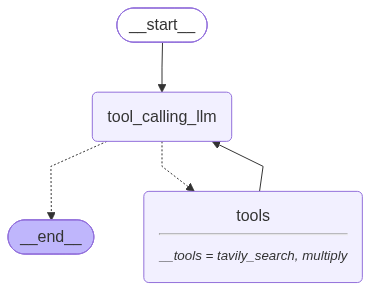

In [ ]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display

## Node defination
def tool_calling_llm(state:State):
    return  {"messages":[llm_with_tool.invoke(state["messages"])]}






##graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))




## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message(result) from assistant is a tool call->tools_condition routes to tools
    #if the latest message(result) is not a tool call ->tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

##compile the graph
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
response = graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})

In [ ]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

I'll fetch the recent AI news and calculate the multiplication for you.
Tool Calls:
  tavily_search (7tk6dnns9)
 Call ID: 7tk6dnns9
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: latest AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  multiply (jabr72f72)
 Call ID: jabr72f72
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.wsj.com/tech/ai", "title": "Artificial Intelligence - Latest AI News and Analysis - WSJ.com", "content": "21\n\nTemasek-backed Vertex Ventures Japan ha

## Adding Memory in Agentic Graph

Without memory, it cant remember anything, look at the examples below, i told my name in first msz, and in next msz i asked , but it completely forgot my name,! so its not persisting the  entire imformation with respectr to the previous conversation or previous interaction that we had

In [ ]:
response = graph.invoke({"messages":" Hello, my name is mamun"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

 Hello, my name is mamun
================================== Ai Message ==================================

Hello Mamun! Nice to meet you. How can I help you today?


In [ ]:
response = graph.invoke({"messages":" Hello, What is my name?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

 Hello, What is my name?
================================== Ai Message ==================================

Hello! I don't know your name. I don't have access to any personal information about you unless you choose to share it with me in our conversation.

If you'd like, you can tell me your name, and I'll be happy to use it!


Langgraph has a very special tool which is called memory to resolve this problem

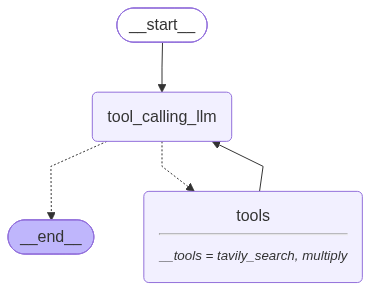

In [ ]:
## state graph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node defination
def tool_calling_llm(state:State):
    return  {"messages":[llm_with_tool.invoke(state["messages"])]}






##graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))




## add edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #if the latest message(result) from assistant is a tool call->tools_condition routes to tools
    #if the latest message(result) is not a tool call ->tools_condition routes to END
    tools_condition
)

builder.add_edge("tools","tool_calling_llm")

##compile the graph
graph = builder.compile(checkpointer = memory)

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
config ={"configurable":{"thread_id":"1"}}
response=graph.invoke({"messages":"Hi my name is Mamun"},config = config)
response

{'messages': [HumanMessage(content='Hi my name is Mamun', additional_kwargs={}, response_metadata={}, id='5dca1e8f-5b72-45a7-8ea6-3c3fe3bbe9be'),
  AIMessage(content='Hi Mamun! Nice to meet you. How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 1916, 'total_tokens': 1933, 'completion_time': 0.032883558, 'completion_tokens_details': None, 'prompt_time': 0.136195085, 'prompt_tokens_details': None, 'queue_time': 0.050246, 'total_time': 0.169078643}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1beda-17db-762a-a8cc-a672a2629211-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1916, 'output_tokens': 17, 'total_tokens': 1933})]}

In [ ]:
response["messages"][-1].content

'Hi Mamun! Nice to meet you. How can I help you today?'

In [ ]:
response=graph.invoke({"messages":"Hi , what is my name?"},config = config)
response

{'messages': [HumanMessage(content='Hi my name is Mamun', additional_kwargs={}, response_metadata={}, id='5dca1e8f-5b72-45a7-8ea6-3c3fe3bbe9be'),
  AIMessage(content='Hi Mamun! Nice to meet you. How can I help you today?', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 1916, 'total_tokens': 1933, 'completion_time': 0.032883558, 'completion_tokens_details': None, 'prompt_time': 0.136195085, 'prompt_tokens_details': None, 'queue_time': 0.050246, 'total_time': 0.169078643}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1beda-17db-762a-a8cc-a672a2629211-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1916, 'output_tokens': 17, 'total_tokens': 1933}),
  HumanMessage(content='Hi , what is my name?', additional_kwargs={}, response_metadata={}, id='923f22ae-77ea-43b5-b456-427d97

In [ ]:
response['messages'][-1].content

'Your name is Mamun.'

In [ ]:
response=graph.invoke({"messages":"Hi , do you remember me?"},config = config)
response['messages'][-1].content

'Yes, I remember you! Your name is Mamun.'

In [ ]:
response=graph.invoke({"messages":"Hi , my name is sneha"},config = config)
response['messages'][-1].content

'Hi Sneha! It’s nice to meet you. How can I help you today?'

In [ ]:
response=graph.invoke({"messages":"Hi , do you remember my name?"},config = config)
response['messages'][-1].content

'Yes, I remember your name is Sneha.'

# streaming

In [41]:
from langgraph.checkpoint.memory import MemorySaver
memory  =  MemorySaver()


In [42]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

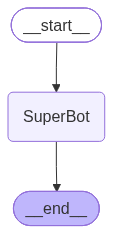

In [44]:
graph = StateGraph(State)

##node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder = graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [46]:
# invocation
config = {"configurable":{"thread_id":"1"}}

graph_builder.invoke({"messages":"Hi my name is mamun and i like cricket"},config)

{'messages': [HumanMessage(content='Hi my name is mamun and i like cricket', additional_kwargs={}, response_metadata={}, id='9552bef2-24f4-4547-9555-640d6312b137'),
  AIMessage(content="Hello Mamun! It's nice to meet you. 🏏\n\nCricket is a wonderful sport with such a rich history and passionate fan base. Who is your favorite team or player? Do you prefer watching the fast-paced T20s or the strategic 5-day Tests?\n\nI’d love to hear more about what you enjoy about cricket!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 73, 'prompt_tokens': 22, 'total_tokens': 95, 'completion_time': 0.151314757, 'completion_tokens_details': None, 'prompt_time': 0.001288642, 'prompt_tokens_details': None, 'queue_time': 0.053887727, 'total_time': 0.152603399}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1bf7b-5380-76b1-a6b9-3c024ee3e

## Streaming

Methods: stream() and astream()

* these methods are sync and async methods for streaming back results

Additional parameters in streaming models fro graph stare
* values: This streams the full state of the graph after each node is called.
* updates: This streams updates to the state of the graph after each node is called


In [49]:
# create a thread
config = {"configurable":{"thread_id":"3"}}
for chunk in graph_builder.stream({"messages":"Hi, my name is mamun and i like cricket"},config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hi Mamun! It's great to meet you. 🏏\n\nCricket is a fantastic sport with so much strategy, skill, and excitement. Since you're a fan, I’d love to know a bit more about your preferences:\n\n*   **Which teams do you support?** (e.g., Bangladesh, India, Australia, England, Pakistan, etc.)\n*   **Who is your favorite player?** (e.g., Shakib Al Hasan, M. Starc, Virat Kohli, Babar Azam, etc.)\n*   **Do you prefer Test matches, ODIs, or T20s?**\n\nAlso, are you following any upcoming series or tournaments right now? I’d be happy to chat about match results, player stats, or cricket history!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 162, 'prompt_tokens': 23, 'total_tokens': 185, 'completion_time': 0.325901988, 'completion_tokens_details': None, 'prompt_time': 0.001301389, 'prompt_tokens_details': None, 'queue_time': 0.048170001, 'total_time': 0.327203377}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint':

In [50]:
for chunk in graph_builder.stream({"messages":"Hi, my name is mamun and i like cricket"},config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, my name is mamun and i like cricket', additional_kwargs={}, response_metadata={}, id='870133d6-1ed8-491c-8364-049a7d4a35ae'), AIMessage(content="Hi Mamun! It's great to meet you. 🏏\n\nCricket is a fantastic sport with so much strategy, skill, and excitement. Since you're a fan, I’d love to know a bit more about your preferences:\n\n*   **Which teams do you support?** (e.g., Bangladesh, India, Australia, England, Pakistan, etc.)\n*   **Who is your favorite player?** (e.g., Shakib Al Hasan, M. Starc, Virat Kohli, Babar Azam, etc.)\n*   **Do you prefer Test matches, ODIs, or T20s?**\n\nAlso, are you following any upcoming series or tournaments right now? I’d be happy to chat about match results, player stats, or cricket history!", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 162, 'prompt_tokens': 23, 'total_tokens': 185, 'completion_time': 0.325901988, 'completion_tokens_details': None, 'prompt_time': 0.001301389, 'p

In [51]:
# create a thread
config = {"configurable":{"thread_id":"4"}}
for chunk in graph_builder.stream({"messages":"Hi, my name is mamun and i like cricket"},config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Mamun! Nice to meet you. 🏏\n\nCricket is a fantastic sport with such a rich history and passionate fan base. Since you like cricket, I’d love to know a bit more:\n\n*   **Who is your favorite player?** (Are you a fan of legends like Sachin Tendulkar, Virat Kohli, or someone else?)\n*   **Which team do you support?** (National team like India, Pakistan, Australia, etc., or a specific franchise in the IPL, PSL, BPL, etc.?)\n*   **Do you prefer watching matches, playing yourself, or analyzing the stats?**\n\nFeel free to share your thoughts, and we can chat about recent matches, player performances, or even cricket trivia! 😊', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 160, 'prompt_tokens': 23, 'total_tokens': 183, 'completion_time': 0.30399658, 'completion_tokens_details': None, 'prompt_time': 0.00129321, 'prompt_tokens_details': None, 'queue_time': 0.052887459, 'total_time': 0.30528979}, 'model_name': 'q

In [52]:
for chunk in graph_builder.stream({"messages":"I also like football"},config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, my name is mamun and i like cricket', additional_kwargs={}, response_metadata={}, id='3468e4f5-67eb-4c45-802d-f4a410d91898'), AIMessage(content='Hi Mamun! Nice to meet you. 🏏\n\nCricket is a fantastic sport with such a rich history and passionate fan base. Since you like cricket, I’d love to know a bit more:\n\n*   **Who is your favorite player?** (Are you a fan of legends like Sachin Tendulkar, Virat Kohli, or someone else?)\n*   **Which team do you support?** (National team like India, Pakistan, Australia, etc., or a specific franchise in the IPL, PSL, BPL, etc.?)\n*   **Do you prefer watching matches, playing yourself, or analyzing the stats?**\n\nFeel free to share your thoughts, and we can chat about recent matches, player performances, or even cricket trivia! 😊', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 160, 'prompt_tokens': 23, 'total_tokens': 183, 'completion_time': 0.30399658, 'completion_tokens_detai

In [54]:
config = {"configurable":{"thread_id":"5"}}

async for event in graph_builder.astream_events({"messages":["hi my name is mamun and i like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['hi my name is mamun and i like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1bf90-38b5-7456-a42a-78a4441405d9', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='hi my name is mamun and i like to play cricket', additional_kwargs={}, response_metadata={}, id='5d29560a-efaf-4d37-aadd-e8172a2f5f32')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a1bf90-38ca-741c-8ae4-622b4b68d465', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:6bc9fcae-2e26-bf42-8b6e-5958fd7d1e1c'}, 'parent_ids': ['01a1bf90-38b5-7456-a42a-78a4441405d9']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':